In [2]:
!pip install nltk scikit-learn textblob wordcloud tensorflow matplotlib


========== Q1 ==========

Cleaned Text: artificial intelligence is changing the world rapidly
machine learning helps computers learn from data
ai is widely used in healthcare education and transportation
researchers develop intelligent systems to solve complex problems
modern technology makes our daily lives easier and more efficient
in the future artificial intelligence will create new opportunities

Words: ['artificial', 'intelligence', 'is', 'changing', 'the', 'world', 'rapidly', 'machine', 'learning', 'helps', 'computers', 'learn', 'from', 'data', 'ai', 'is', 'widely', 'used', 'in', 'healthcare', 'education', 'and', 'transportation', 'researchers', 'develop', 'intelligent', 'systems', 'to', 'solve', 'complex', 'problems', 'modern', 'technology', 'makes', 'our', 'daily', 'lives', 'easier', 'and', 'more', 'efficient', 'in', 'the', 'future', 'artificial', 'intelligence', 'will', 'create', 'new', 'opportunities']

Sentences: ['Artificial intelligence is changing the world rapidly.', '

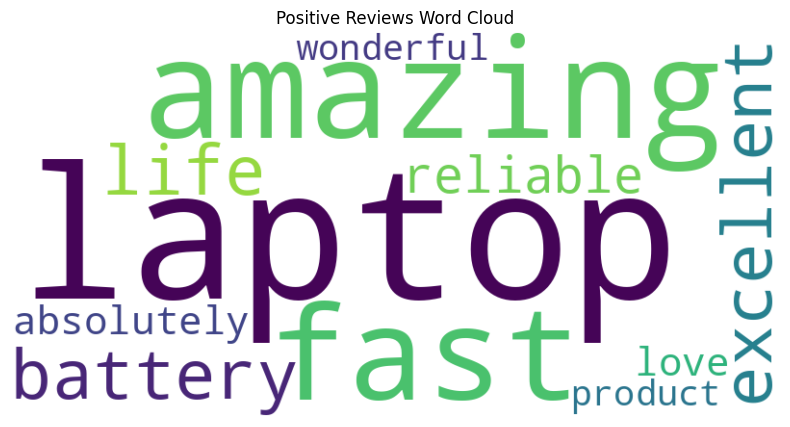


Polarity: -1 to +1
Subjectivity: 0 to 1

========== Q6 ==========

Vocabulary Size: 76
Training X Shape: (97, 7)
Training y Shape: (97,)

Training Completed

Generated Line 1:
artificial intelligence is technology technology work more more tasks skills

Generated Line 2:
machine learning learning automation and learn data data data tasks

Generated Line 3:
technology learning to to learn from lives lives tasks

========== ALL QUESTIONS COMPLETED ==========


In [3]:

# Install required libraries (Google Colab / Jupyter)
# Uncomment if needed:
# %pip install nltk scikit-learn textblob wordcloud tensorflow matplotlib

import re
import nltk
import numpy as np
import matplotlib.pyplot as plt

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, WordNetLemmatizer

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from textblob import TextBlob
from wordcloud import WordCloud

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)


# ==================================================
# Q1. TEXT PREPROCESSING AND FREQUENCY DISTRIBUTION
# ==================================================

print("\n========== Q1 ==========")

text = """Artificial intelligence is changing the world rapidly.
Machine learning helps computers learn from data.
AI is widely used in healthcare, education, and transportation.
Researchers develop intelligent systems to solve complex problems.
Modern technology makes our daily lives easier and more efficient.
In the future, artificial intelligence will create new opportunities."""

# 1. Lowercase and remove punctuation
cleaned = re.sub(r'[^\w\s]', '', text.lower())
print("\nCleaned Text:", cleaned)

# 2. Word and sentence tokenization
words = word_tokenize(cleaned)
sentences = sent_tokenize(text)

print("\nWords:", words)
print("\nSentences:", sentences)

# 3. split() vs word_tokenize()
print("\nPython split():", text.split())
print("\nNLTK word_tokenize():", word_tokenize(text))

# 4. Stopword removal
stop_words = set(stopwords.words('english'))
filtered = [w for w in words if w not in stop_words]

print("\nWithout Stopwords:", filtered)

# 5. Frequency distribution
freq = FreqDist(filtered)
print("\nWord Frequencies:", freq.most_common())


# ==================================================
# Q2. REGEX, STEMMING AND LEMMATIZATION
# ==================================================

print("\n========== Q2 ==========")

# 1. Extract alphabetic words
words2 = re.findall(r'[a-zA-Z]+', text.lower())
print("\nAlphabetic Words:", words2)

# 2. Remove stopwords
filtered2 = [w for w in words2 if w not in stop_words]
print("\nFiltered Words:", filtered2)

# 3. Stemming
stemmer = PorterStemmer()
stemmed = [stemmer.stem(w) for w in filtered2]

print("\nStemmed:", stemmed)

# 4. Lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized = [lemmatizer.lemmatize(w) for w in filtered2]

print("\nLemmatized:", lemmatized)

# 5. Comparison
print("\nOriginal | Stemmed | Lemmatized")
for w, s, l in zip(filtered2, stemmed, lemmatized):
    print(w, "|", s, "|", l)

print("\nStemming is faster but may produce non-dictionary words.")
print("Lemmatization produces dictionary base forms.")
print("Prefer stemming for fast search and lemmatization for linguistic analysis.")


# ==================================================
# Q3. BAG OF WORDS AND TF-IDF
# ==================================================

print("\n========== Q3 ==========")

texts = [
    "Artificial intelligence improves healthcare and medical diagnosis",
    "Machine learning improves technology and artificial intelligence",
    "Healthcare technology helps doctors diagnose medical problems"
]

# 1. Bag of Words
cv = CountVectorizer()
bow = cv.fit_transform(texts)

print("\nBoW Features:", cv.get_feature_names_out())
print("\nBoW Matrix:\n", bow.toarray())

# 2. TF-IDF
tfidf_vectorizer = TfidfVectorizer()
tfidf = tfidf_vectorizer.fit_transform(texts)

print("\nTF-IDF Matrix:\n", tfidf.toarray())

# 3. Top 3 keywords
features = tfidf_vectorizer.get_feature_names_out()

for i in range(len(texts)):
    scores = tfidf.toarray()[i]
    top = np.argsort(scores)[::-1][:3]

    print("\nText", i + 1, "Top 3 Keywords:")

    for index in top:
        print(features[index], ":", round(scores[index], 4))

print("\nBoW counts word occurrences.")
print("TF-IDF highlights important words across documents.")


# ==================================================
# Q4. JACCARD AND COSINE SIMILARITY
# ==================================================

print("\n========== Q4 ==========")

text1 = """Artificial intelligence uses data to learn patterns.
Machine learning helps computers make predictions.
AI systems improve healthcare and education.
Neural networks process large amounts of information.
Intelligent systems automate complex tasks."""

text2 = """Blockchain is a distributed ledger technology.
It stores transactions securely across networks.
Blockchain improves transparency and data security.
Smart contracts automate digital transactions.
Decentralized systems reduce dependence on intermediaries."""

# 1. Preprocessing
def preprocess(t):
    t = re.sub(r'[^a-z\s]', '', t.lower())
    return t.split()

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)

print("\nTokens 1:", tokens1)
print("\nTokens 2:", tokens2)

# 2a. Jaccard Similarity
set1 = set(tokens1)
set2 = set(tokens2)

jaccard = len(set1 & set2) / len(set1 | set2)

print("\nJaccard Similarity:", jaccard)

# 2b. Cosine Similarity
vectorizer = TfidfVectorizer(stop_words='english')
matrix = vectorizer.fit_transform([text1, text2])

cosine = cosine_similarity(matrix[0:1], matrix[1:2])[0][0]

print("Cosine Similarity:", cosine)

# 2c. Analysis
print("\nJaccard compares unique word overlap.")
print("TF-IDF cosine compares weighted word vectors.")
print("Cosine is more informative here because common words")
print("receive less importance, but neither captures full meaning.")


# ==================================================
# Q5. SENTIMENT ANALYSIS AND WORD CLOUD
# ==================================================

print("\n========== Q5 ==========")

reviews = [
    "This laptop is amazing and very fast.",
    "The battery life is excellent and reliable.",
    "The product is terrible and disappointing.",
    "The delivery was slow and the packaging was bad.",
    "The laptop has a screen and keyboard.",
    "I absolutely love this wonderful product."
]

positive_reviews = []

# 1. Polarity and subjectivity
# 2. Sentiment classification
for review in reviews:
    blob = TextBlob(review)

    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("\nReview:", review)
    print("Polarity:", polarity)
    print("Subjectivity:", subjectivity)
    print("Sentiment:", sentiment)

# 3. Word cloud for positive reviews
positive_text = " ".join(positive_reviews)

if positive_text:
    cloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(positive_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Positive Reviews Word Cloud")
    plt.show()

print("\nPolarity: -1 to +1")
print("Subjectivity: 0 to 1")


# ==================================================
# Q6. NEXT WORD PREDICTION USING LSTM
# ==================================================

print("\n========== Q6 ==========")

training_text = """Artificial intelligence is transforming modern technology.
Machine learning allows computers to learn from data.
Artificial intelligence helps doctors detect diseases.
Machine learning improves predictions in healthcare.
Technology makes communication faster and easier.
Artificial intelligence is useful in education.
Students use technology to learn new skills.
Intelligent systems can solve complex problems.
Machine learning models identify patterns in data.
Artificial intelligence improves business decisions.
Technology continues to change our daily lives.
Researchers build intelligent systems for the future.
Machine learning supports automation and innovation.
Artificial intelligence creates new opportunities.
Computers process information using advanced algorithms.
Modern technology helps people work more efficiently.
Intelligent machines can assist humans in many tasks.
Artificial intelligence will shape the future."""

# 1. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])

total_words = len(tokenizer.word_index) + 1
print("\nVocabulary Size:", total_words)

# 2. Create input sequences
sequences = []

for line in training_text.split("."):
    tokens = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(tokens)):
        sequences.append(tokens[:i + 1])

max_len = max(len(seq) for seq in sequences)

sequences = pad_sequences(
    sequences,
    maxlen=max_len,
    padding="pre"
)

X = sequences[:, :-1]
y = sequences[:, -1]

print("Training X Shape:", X.shape)
print("Training y Shape:", y.shape)

# 3. Build LSTM model
model = Sequential([
    Embedding(total_words, 50),
    LSTM(100),
    Dense(total_words, activation="softmax")
])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

# Train
model.fit(X, y, epochs=100, verbose=0)
print("\nTraining Completed")

# 4. Generate new text
def generate_text(seed, n_words):
    for _ in range(n_words):

        seq = tokenizer.texts_to_sequences([seed])[0]

        seq = pad_sequences(
            [seq],
            maxlen=max_len - 1,
            padding="pre"
        )

        prediction = model.predict(seq, verbose=0)
        predicted_id = np.argmax(prediction, axis=-1)[0]

        word = tokenizer.index_word.get(predicted_id, "")

        if not word:
            break

        seed += " " + word

    return seed

print("\nGenerated Line 1:")
print(generate_text("artificial intelligence", 8))

print("\nGenerated Line 2:")
print(generate_text("machine learning", 8))

print("\nGenerated Line 3:")
print(generate_text("technology", 8))

print("\n========== ALL QUESTIONS COMPLETED ==========")
